# Лабораторная работа 5

Численное решение начально-краевой задачи для уравнения параболического типа.

**Вариант 8**.

$$u_t=a u_{xx}+cu,\qquad a>0,\quad c<0,\quad 0<x<\frac{\pi}{2},$$
$$u_x(0,t)=e^{(c-a)t},\qquad u\left(\frac{\pi}{2},t\right)=e^{(c-a)t},\qquad u(x,0)=\sin x.$$

Точное решение:
$$U(x,t)=e^{(c-a)t}\sin x.$$

В расчётах выбраны $a=1$, $c=-1$, $T=0.1$. Это параметры эксперимента, удовлетворяющие ограничениям варианта. Левая граница — условие второго рода, правая — первого рода.

Сравниваем явную, неявную схемы и Кранка–Николсона, все три аппроксимации левой границы, погрешности в разные моменты времени и зависимость от $h$ и $\tau$.

In [1]:
from pathlib import Path
import sys

# Добавляем каталог пакета, чтобы импорт работал и при запуске из labs/.
project_root = Path.cwd()
if project_root.name == "labs":
    project_root = project_root.parent
package_root = project_root / "src" if (project_root / "src" / "nm").is_dir() else project_root
sys.path.insert(0, str(package_root))

import numpy as np
import matplotlib.pyplot as plt
from nm.pde.parabolic import BoundaryCondition, solve_parabolic

%matplotlib inline

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True})

a = 1.0
c = -1.0
T = 0.1
L = np.pi / 2


def initial(x):
    return np.sin(x)


def exact_solution(x, t):
    return np.exp((c - a) * t) * initial(x)


def zero_source(x, t):
    return np.zeros_like(x)


# В коде alpha*u + beta*u_x = g(t); производная вдоль x на обоих концах.
left_boundary = BoundaryCondition(0.0, 1.0, lambda t: np.exp((c - a) * t))
right_boundary = BoundaryCondition(1.0, 0.0, lambda t: np.exp((c - a) * t))
methods = [("Явная", 0.0), ("Неявная", 1.0), ("Кранк–Николсон", 0.5)]


def solve_variant(nx, nt, theta, boundary_order="2p2"):
    return solve_parabolic(
        a=a, b=0.0, c=c, source=zero_source, initial=initial,
        left_boundary=left_boundary, right_boundary=right_boundary,
        left=0.0, right=L, final_time=T, nx=nx, nt=nt,
        theta=theta, boundary_order=boundary_order,
    )

## Разностные схемы

Пусть $x_j=jh$, $h=L/n_x$, $t_k=k\tau$, $\sigma=a\tau/h^2$. Введём
$$L_hu_j=a\frac{u_{j-1}-2u_j+u_{j+1}}{h^2}+cu_j.$$
Три схемы записываются одной формулой:
$$\frac{u_j^{k+1}-u_j^k}{\tau}=\theta L_hu_j^{k+1}+(1-\theta)L_hu_j^k.$$

- $\theta=0$: явная схема, порядок $O(\tau+h^2)$.
- $\theta=1$: неявная схема, порядок $O(\tau+h^2)$.
- $\theta=1/2$: Кранк–Николсон, порядок $O(\tau^2+h^2)$.

Для явной схемы код проверяет достаточное условие неотрицательности весов:
$$\tau\left(\frac{2a}{h^2}-c\right)\leq1.$$
При $c=0$ оно превращается в $\sigma\leq1/2$. При $c<0$ одного условия $\sigma\leq1/2$ для этой проверки недостаточно. Для двухточечной границы второго порядка диагональный коэффициент здесь такой же, поэтому это ограничение проверяет и граничный шаг.

При $\theta>0$ внутренние строки СЛАУ имеют диагонали $-\theta\sigma$, $1+2\theta\sigma-\theta\tau c$, $-\theta\sigma$. Используется прогонка. Для трёхточечной границы сначала исключается лишний элемент через соседнюю внутреннюю строку.

Для данной задачи неявная схема и Кранк–Николсон с основной аппроксимацией `2p2` безусловно устойчивы: пространственный оператор с однородными условиями Неймана слева и Дирихле справа имеет отрицательные собственные значения, дополнительно сдвинутые на $c<0$. Это не означает точность при большом $\tau$.

In [2]:
nx, nt = 40, 400
h, tau = L / nx, T / nt
print(f"h={h:g}, tau={tau:g}, sigma={a * tau / h**2:g}")
print(f"Проверка явных весов: tau*(2a/h²-c)={tau*(2*a/h**2-c):.6f} <= 1")

# U[k, j] хранит значение в момент t[k] и точке x[j].
# Все методы сравниваем на одной и той же сетке.
solutions = {}
for name, theta in methods:
    x, t, values = solve_variant(nx, nt, theta)
    solutions[name] = values

# Broadcasting строит точное решение сразу на всей пространственно-временной сетке.
exact_values = exact_solution(x[None, :], t[:, None])
errors = {name: np.max(np.abs(values - exact_values), axis=1)
          for name, values in solutions.items()}

print("\nМаксимальная по x абсолютная погрешность E(t) = max_j |u_j - U(x_j,t)|")
print(f"{'t':>8}" + "".join(f"{name:>20}" for name, _ in methods))
for requested_time in [0.0, 0.025, 0.05, 0.075, T]:
    # Ближайший узел времени; печатаем именно его фактическое значение.
    k = np.argmin(np.abs(t - requested_time))
    print(f"{t[k]:8.4f}" + "".join(f"{errors[name][k]:20.6e}" for name, _ in methods))

h=0.0392699, tau=0.00025, sigma=0.162114
Проверка явных весов: tau*(2a/h²-c)=0.324478 <= 1

Максимальная по x абсолютная погрешность E(t) = max_j |u_j - U(x_j,t)|
       t               Явная             Неявная      Кранк–Николсон
  0.0000        0.000000e+00        0.000000e+00        0.000000e+00
  0.0250        4.492231e-05        4.198071e-05        4.345637e-05
  0.0500        6.244366e-05        5.469966e-05        5.857732e-05
  0.0750        7.505802e-05        6.152106e-05        6.829520e-05
  0.1000        8.498980e-05        6.510321e-05        7.505152e-05


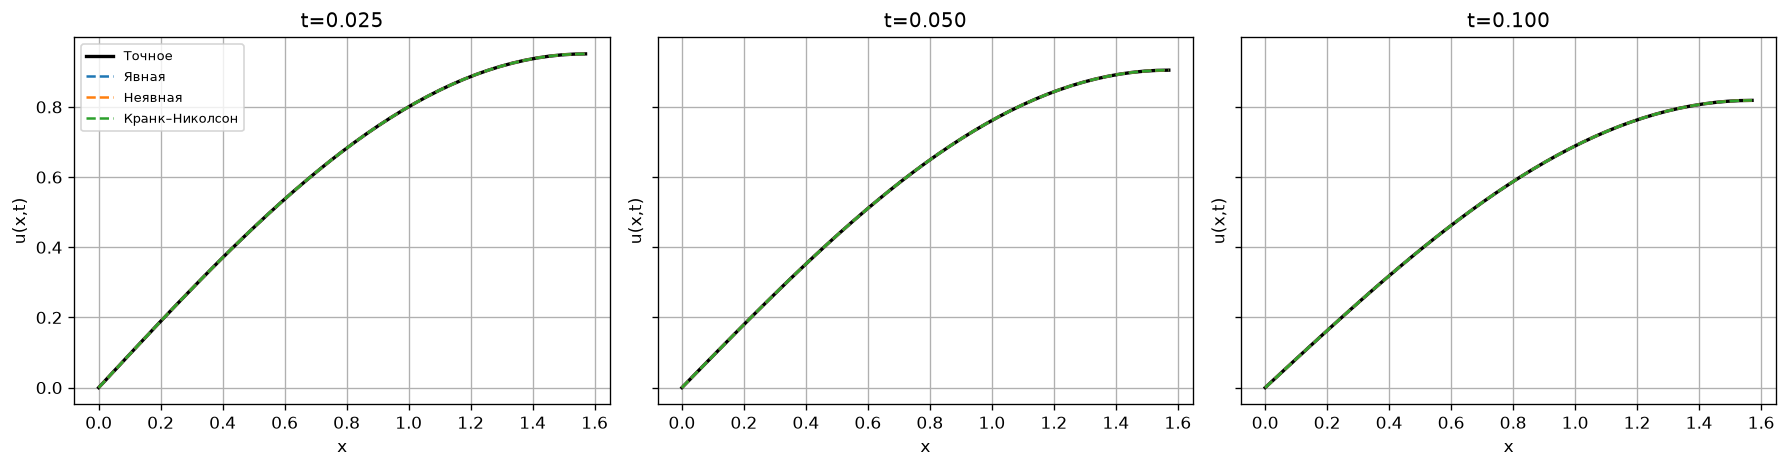

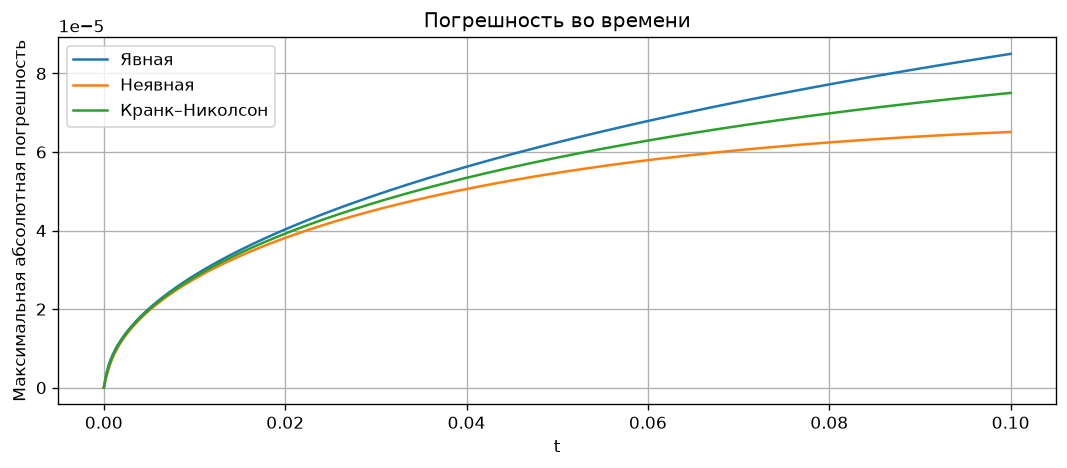

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, requested_time in zip(axes, [0.025, 0.05, T]):
    k = np.argmin(np.abs(t - requested_time))
    ax.plot(x, exact_values[k], "k-", linewidth=2, label="Точное")
    for name, _ in methods:
        ax.plot(x, solutions[name][k], "--", label=name)
    ax.set(title=f"t={t[k]:.3f}", xlabel="x", ylabel="u(x,t)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, _ in methods:
    plt.plot(t, errors[name], label=name)
plt.xlabel("t")
plt.ylabel("Максимальная абсолютная погрешность")
plt.title("Погрешность во времени")
plt.legend()
plt.tight_layout()
plt.show()

## Зависимость от пространственного шага

Изменяем $h$, сохраняя малый шаг времени $\tau=T/4000$. Сравниваем решения с точным на последнем слое. Для явной схемы проверяем условие устойчивости и на самой мелкой сетке.

Оценка наблюдаемого порядка: $p=\log_2(E(h)/E(h/2))$. При фиксированном $\tau$ временная ошибка в конце концов ограничит уменьшение общей ошибки. Возможна также частичная компенсация пространственной и временной ошибок — поэтому отдельное значение $p$ не заменяет теоретический порядок.

Схема                 nx       h         ошибка         p
Явная                  10   0.15708  1.186059e-03      nan
Явная                  20   0.07854  3.004342e-04    1.981
Явная                  40   0.03927  7.604496e-05    1.982
Явная                  80   0.01963  1.976801e-05    1.944
Неявная                10   0.15708  1.184032e-03      nan
Неявная                20   0.07854  2.984387e-04    1.988
Неявная                40   0.03927  7.405630e-05    2.011
Неявная                80   0.01963  1.778099e-05    2.058
Кранк–Николсон         10   0.15708  1.185046e-03      nan
Кранк–Николсон         20   0.07854  2.994365e-04    1.985
Кранк–Николсон         40   0.03927  7.505068e-05    1.996
Кранк–Николсон         80   0.01963  1.877455e-05    1.999


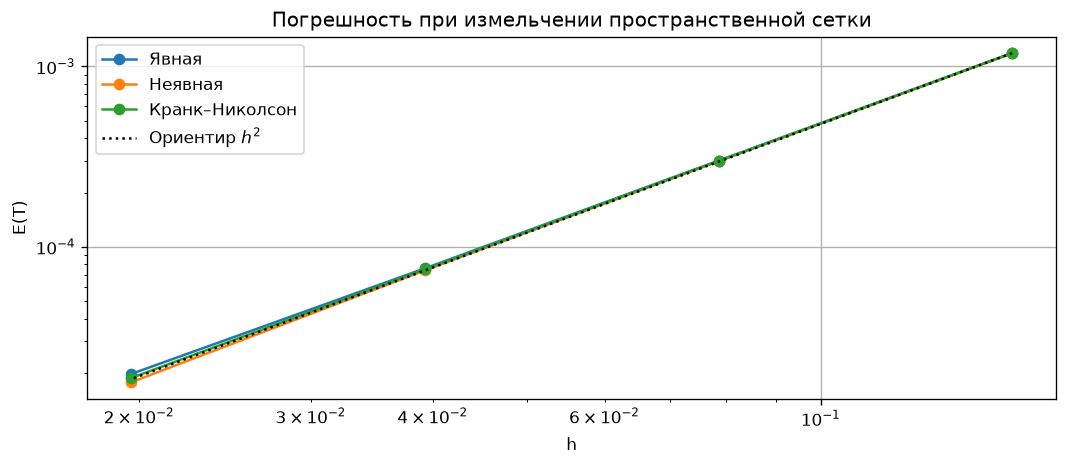

In [4]:
space_counts = [10, 20, 40, 80]
space_errors = {name: [] for name, _ in methods}
print("Схема                 nx       h         ошибка         p")
for name, theta in methods:
    previous_error = None
    for n in space_counts:
        xs, ts, us = solve_variant(n, 4000, theta)
        error = np.max(np.abs(us[-1] - exact_solution(xs, ts[-1])))
        space_errors[name].append(error)
        order = np.nan if previous_error is None else np.log2(previous_error / error)
        print(f"{name:20} {n:4d} {L/n:9.5f} {error:13.6e} {order:8.3f}")
        previous_error = error

hs = L / np.array(space_counts)
for name, _ in methods:
    plt.loglog(hs, space_errors[name], "o-", label=name)
plt.loglog(hs, space_errors["Кранк–Николсон"][0] * (hs / hs[0])**2,
           "k:", label="Ориентир $h^2$")
plt.xlabel("h")
plt.ylabel("E(T)")
plt.title("Погрешность при измельчении пространственной сетки")
plt.legend()
plt.tight_layout()
plt.show()

При фиксированном малом $\tau$ ожидается уменьшение пространственной ошибки примерно как $h^2$. На мелких сетках временная ошибка явной и неявной схем может ограничить это уменьшение или частично компенсировать пространственную ошибку. Наблюдаемый порядок вычисляется из фактических ошибок и не подменяет теоретический порядок.

## Зависимость от шага времени

Фиксируем $h=L/40$ и уменьшаем $\tau$. Показываем полную ошибку относительно $U(x,t)$ и временную ошибку относительно точного решения полудискретной системы с границей `2p2`.

Для отделения временной ошибки исключаем известное правое граничное значение и записываем полудискретную систему для $v=(u_0,\ldots,u_{N-1})$:
$$v'=Av+f e^{\mu t},\qquad \mu=c-a.$$
В первой строке $A_{00}=c-2a/h^2$, $A_{01}=2a/h^2$; во внутренних строках стоят обычные центральные разности. Вектор $f$ содержит $f_0=-2a/h$ от левого условия и $f_{N-1}=a/h^2$ от правого.

Положим $q=(\mu I-A)^{-1}f$. Тогда точное решение этой системы:
$$v(t)=e^{At}(v(0)-q)+e^{\mu t}q.$$
Матричную экспоненту вычисляем через собственные значения. Так пространственная ошибка не маскирует первый порядок по времени явной/неявной схем и второй порядок Кранка–Николсона. Полную ошибку вычисляем относительно $U$.

Схема                 nt        tau       полная        временная       p(tau)
Явная                 400  2.5000e-04  8.498980e-05  3.110391e-05      nan
Явная                 800  1.2500e-04  8.002128e-05  1.554717e-05    1.000
Явная                1600  6.2500e-05  7.753624e-05  7.772393e-06    1.000
Явная                3200  3.1250e-05  7.629352e-05  3.885898e-06    1.000
Неявная               400  2.5000e-04  6.510321e-05  3.106572e-05      nan
Неявная               800  1.2500e-04  7.007798e-05  1.553763e-05    1.000
Неявная              1600  6.2500e-05  7.256459e-05  7.770006e-06    1.000
Неявная              3200  3.1250e-05  7.380769e-05  3.885302e-06    1.000
Кранк–Николсон        400  2.5000e-04  7.505152e-05  2.587561e-09      nan
Кранк–Николсон        800  1.2500e-04  7.505088e-05  6.469338e-10    2.000
Кранк–Николсон       1600  6.2500e-05  7.505073e-05  1.615362e-10    2.002
Кранк–Николсон       3200  3.1250e-05  7.505069e-05  4.065503e-11    1.990


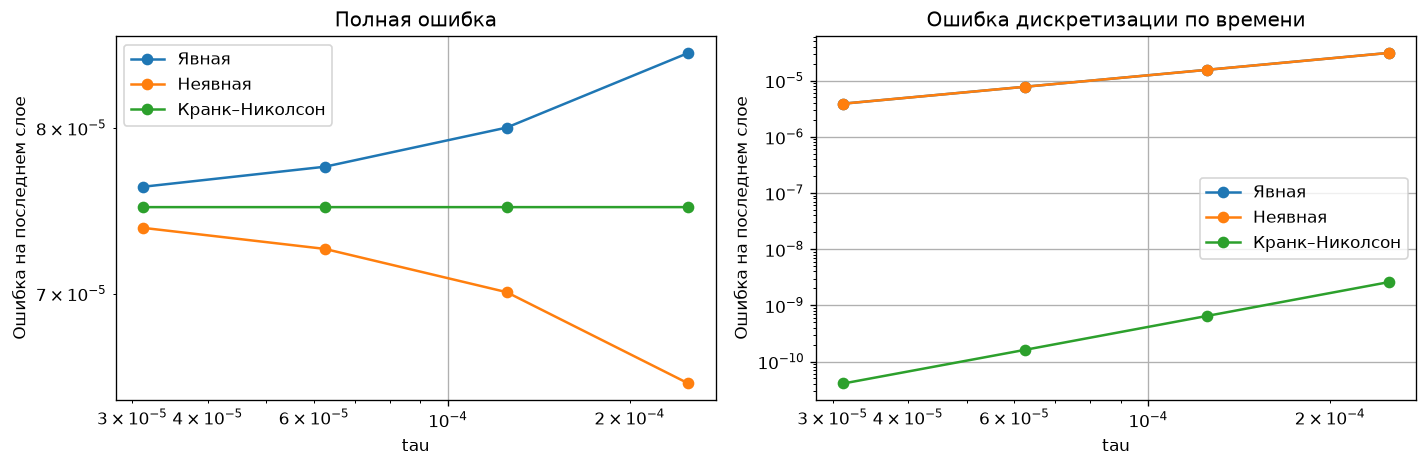

In [5]:
def semidiscrete_solution(nx, time):
    xs = np.linspace(0.0, L, nx + 1)
    h = L / nx
    mu = c - a
    matrix = np.diag(np.full(nx, c - 2*a/h**2))
    matrix += np.diag(np.full(nx - 1, a/h**2), 1)
    matrix += np.diag(np.full(nx - 1, a/h**2), -1)
    matrix[0, 1] = 2*a/h**2
    forcing = np.zeros(nx)
    forcing[0] = -2*a/h
    forcing[-1] = a/h**2
    particular = np.linalg.solve(mu*np.eye(nx) - matrix, forcing)
    # D*A*D^{-1} симметрична при D[0,0]=1/sqrt(2).
    # Используем eigh, чтобы избежать комплексных чисел и получить
    # ортогональный базис собственных векторов.
    scale = np.ones(nx)
    scale[0] = 1/np.sqrt(2)
    symmetric = scale[:, None]*matrix/scale[None, :]
    eigenvalues, eigenvectors = np.linalg.eigh(symmetric)
    coefficients = eigenvectors.T @ (scale*(initial(xs[:-1]) - particular))
    transient = (eigenvectors @ (np.exp(eigenvalues*time)*coefficients))/scale
    return np.r_[transient + np.exp(mu*time)*particular, np.exp(mu*time)]


time_counts = [400, 800, 1600, 3200]
time_errors = {name: [] for name, _ in methods}
full_errors = {name: [] for name, _ in methods}
print("Схема                 nt        tau       полная        временная       p(tau)")
for name, theta in methods:
    previous_error = None
    for m in time_counts:
        xs, ts, us = solve_variant(40, m, theta)
        semidiscrete = semidiscrete_solution(40, T)
        error = np.max(np.abs(us[-1] - semidiscrete))
        full_error = np.max(np.abs(us[-1] - exact_solution(xs, T)))
        time_errors[name].append(error)
        full_errors[name].append(full_error)
        order = np.nan if previous_error is None else np.log2(previous_error / error)
        print(f"{name:20} {m:4d} {T/m:11.4e} {full_error:13.6e} {error:13.6e} {order:8.3f}")
        previous_error = error

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
taus = T / np.array(time_counts)
for name, _ in methods:
    axes[0].loglog(taus, full_errors[name], "o-", label=name)
    axes[1].loglog(taus, time_errors[name], "o-", label=name)
for ax, title in zip(axes, ["Полная ошибка", "Ошибка дискретизации по времени"]):
    ax.set(xlabel="tau", ylabel="Ошибка на последнем слое", title=title)
    ax.legend()
fig.tight_layout()
plt.show()

## Три способа аппроксимации границ и их вывод

В варианте 8 производная задана слева: $u_x(0,t)=g(t)$, $g(t)=e^{(c-a)t}$. Справа $u_N^k=g(t_k)$ задаётся точно при любом способе аппроксимации.

**Две точки, первый порядок (`2p1`).** Из разложения
$$u(h,t)=u(0,t)+hu_x(0,t)+\frac{h^2}{2}u_{xx}(0,t)+O(h^3)$$
получаем $u_x(0,t)=(u_1-u_0)/h+O(h)$. На новом слое:
$$-u_0^{k+1}+u_1^{k+1}=h g(t_{k+1}).$$

**Три точки, второй порядок (`3p2`).** Разложим также
$$u(2h,t)=u(0,t)+2hu_x(0,t)+2h^2u_{xx}(0,t)+O(h^3).$$
В комбинации $-3u(0,t)+4u(h,t)-u(2h,t)$ сокращаются постоянный член и член с $u_{xx}$; остаётся $2hu_x+O(h^3)$. Поэтому
$$\frac{-3u_0^{k+1}+4u_1^{k+1}-u_2^{k+1}}{2h}=g(t_{k+1})$$
имеет погрешность $O(h^2)$. В неявных схемах $u_2^{k+1}$ исключается через строку $j=1$, чтобы сохранить трёхдиагональность.

**Две точки, второй порядок (`2p2`).** Из первого разложения:
$$u_x(0,t)=\frac{u_1-u_0}{h}-\frac h2u_{xx}(0,t)+O(h^2).$$
Используем исходное уравнение $u_{xx}=(u_t-cu)/a$ и условие $u_x=g$:
$$u_t(0,t)=\frac{2a}{h^2}(u_1-u_0)-\frac{2a}{h}g(t)+cu_0+O(h).$$
Для этой граничной строки применяем ту же схему с весами по времени, что и внутри. Код получает равносильную формулу исключением фиктивного узла. В исходной формуле для $u_x$ пространственная погрешность $O(h^2)$; после умножения на $2a/h$ остаток граничной строки для $u_t$ становится $O(h)$. Это не противоречит наблюдаемому второму порядку глобальной ошибки.

При использовании обратной разности для $u_t$ в формуле для $u_x$ временная добавка имеет порядок $O(h\tau)$; Кранк–Николсон вместо этого взвешивает граничный оператор по обоим слоям.

Ниже сравниваем все девять сочетаний схем и аппроксимаций границ. Для его точного решения $u_{xx}(0,t)=0$, поэтому ведущий член ошибки `2p1` исчезает и этот пример не демонстрирует общий первый порядок. Дополнительная проверка на задаче с ненулевым $u_{xx}(0,t)$ показывает различие первого и второго порядков.

In [6]:
boundary_modes = ["2p1", "3p2", "2p2"]
print("Вариант 8: ошибка на последнем слое для всех схем и границ")
print("Схема                Граница       nx=20          nx=40       p")
for name, theta in methods:
    for mode in boundary_modes:
        boundary_errors = []
        for n in [20, 40]:
            # tau пропорционален h², чтобы увидеть пространственный порядок.
            xb, tb, ub = solve_variant(n, 2*n*n, theta, mode)
            boundary_errors.append(np.max(np.abs(ub[-1] - exact_solution(xb, T))))
            assert np.allclose(ub[:, -1], np.exp((c-a)*tb), atol=1e-12)
        e1, e2 = boundary_errors
        print(f"{name:20} {mode:6} {e1:14.6e} {e2:14.6e} {np.log2(e1/e2):7.3f}")

# Контроль порядков на точном решении с ненулевой кривизной на границе.
# w=exp(t)*(1+x+x²+sin(x)), w_t=a*w_xx+c*w+f на [0,L].
# Слева w_x=2*exp(t), справа w=exp(t)*(1+L+L²+sin(L)).
def control_initial(x):
    return 1 + x + x*x + np.sin(x)


def control_source(x, t):
    return np.exp(t)*((1-c)*control_initial(x) - a*(2-np.sin(x)))


control_left = BoundaryCondition(0.0, 1.0, lambda t: 2*np.exp(t))
control_right = BoundaryCondition(1.0, 0.0, lambda t: np.exp(t)*control_initial(L))
print("\nКонтроль с ненулевой кривизной на границе: наблюдаемый порядок")
for name, theta in methods:
    for mode in boundary_modes:
        control_errors = []
        for n in [20, 40, 80]:
            xc, tc, uc = solve_parabolic(
                a, 0.0, c, control_source, control_initial,
                control_left, control_right, 0.0, L, T, n, 2*n*n, theta, mode,
            )
            control_errors.append(np.max(np.abs(uc - np.exp(tc[:,None])*control_initial(xc))))
        orders = np.log2(np.array(control_errors[:-1])/control_errors[1:])
        print(f"{name:20} {mode:6} p={orders[0]:.3f}, {orders[1]:.3f}")

Вариант 8: ошибка на последнем слое для всех схем и границ
Схема                Граница       nx=20          nx=40       p
Явная                2p1      3.383907e-04   8.042910e-05   2.073
Явная                3p2      6.314302e-04   1.569496e-04   2.008
Явная                2p2      3.044242e-04   7.629352e-05   1.996
Неявная              2p1      3.268040e-04   7.774208e-05   2.072
Неявная              3p2      6.417683e-04   1.594591e-04   2.009
Неявная              2p2      2.944468e-04   7.380769e-05   1.996
Кранк–Николсон       2p1      3.325985e-04   7.908566e-05   2.072
Кранк–Николсон       3p2      6.365980e-04   1.582043e-04   2.009
Кранк–Николсон       2p2      2.994367e-04   7.505069e-05   1.996

Контроль с ненулевой кривизной на границе: наблюдаемый порядок
Явная                2p1    p=1.073, 1.037
Явная                3p2    p=2.012, 2.003
Явная                2p2    p=1.995, 1.999
Неявная              2p1    p=1.073, 1.037
Неявная              3p2    p=2.013, 2.003
Неяв

## Выводы

Решена задача варианта 8: $u_t=a u_{xx}+cu$ на $[0,\pi/2]$ с производной слева и заданной температурой справа. Все три схемы сравниваются с $U(x,t)=e^{(c-a)t}\sin x$; реализованы и проверены три способа аппроксимации левой границы.

Явная схема использует ограничение $\tau(2a/h^2-c)\leq1$. Неявная и Кранк–Николсон с `2p2` для данной задачи безусловно устойчивы. Сравнение с полудискретным эталоном позволяет отдельно проверить первый временной порядок явной и неявной схем и второй порядок Кранка–Николсона.

Изменение только $h$ или только $\tau$ не обязано монотонно уменьшать полную ошибку: пространственная и временная составляющие могут компенсироваться, а фиксированный шаг ограничивает точность. Для исходной синусоиды исчезает ведущий член ошибки `2p1` на левой границе; контрольный пример с ненулевой кривизной показывает её общий первый порядок и второй порядок двух остальных аппроксимаций.

На основной сетке $E(T)$ составляет примерно $8.50\cdot10^{-5}$ для явной схемы, $6.51\cdot10^{-5}$ для неявной и $7.51\cdot10^{-5}$ для Кранка–Николсона. Меньшая полная ошибка неявной схемы на этой сетке объясняется компенсацией временной и пространственной ошибок; её временной порядок остаётся первым.
